In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r"d:\thony\used_cars_prediction\data\vehicles.csv")

In [3]:
features = [
    'year',
    'manufacturer',
    'odometer',
    'fuel',
    'transmission',
    'title_status',
    'type',
    'state'
]

target = 'price'

df_ml = df[features + [target]].copy()

print(df_ml.shape)
print(df_ml.isnull().sum())

(426880, 9)
year             1205
manufacturer    17646
odometer         4400
fuel             3013
transmission     2556
title_status     8242
type            92858
state               0
price               0
dtype: int64


In [4]:
df_ml[df_ml['price'] < 0]


,year,manufacturer,odometer,fuel,transmission,title_status,type,state,price


In [5]:
important_columns = [
    'year',
    'manufacturer',
    'odometer',
    'price'
]

df_ml = df_ml.dropna(subset=important_columns)

In [6]:
print(df_ml.shape)
print(df_ml.isnull().sum())

(405077, 9)
year                0
manufacturer        0
odometer            0
fuel             2009
transmission     1624
title_status     7204
type            85533
state               0
price               0
dtype: int64


In [ ]:
df_ml = df_ml[df_ml['price'] <= 57050]
df_ml = df_ml[df_ml['price'] > 500]
df_ml = df_ml[df_ml['year'] >= 1990]

In [8]:
columns_to_fill = [
    'fuel',
    'transmission',
    'title_status',
    'type'
]

df_ml[columns_to_fill] = df_ml[columns_to_fill].fillna('unknown')

In [9]:
import numpy as np

df_ml['price'] = np.log1p(df_ml['price'])
df_ml['odometer'] = np.log1p(df_ml['odometer'])
year_centered = df_ml['year'] - df_ml['year'].mean()
df_ml['year_squared'] = year_centered ** 2
df_ml['odometer_squared'] = df_ml['odometer'] ** 2
df_ml['car_age'] = 2026 - df_ml['year']
df_ml['age_odometer_interaction'] = (
    df_ml['year'] * df_ml['odometer']
)

In [10]:
df_encoded = pd.get_dummies(df_ml, columns=['manufacturer', 'fuel', 'transmission', 'title_status', 'type', 'state'])
df_encoded.head()

,year,odometer,price,year_squared,odometer_squared,car_age,age_odometer_interaction,manufacturer_acura,manufacturer_alfa-romeo,manufacturer_aston-martin,...,state_sd,state_tn,state_tx,state_ut,state_va,state_vt,state_wa,state_wi,state_wv,state_wy
27,2014.0,10.966887,10.422013,8.024475,120.272612,12.0,22087.310590,False,False,False,...,False,False,False,False,False,False,False,False,False,False
28,2010.0,11.173669,10.025307,1.362472,124.850887,16.0,22459.075408,False,False,False,...,False,False,False,False,False,False,False,False,False,False
29,2020.0,9.860632,10.586357,78.017479,97.232068,6.0,19918.477129,False,False,False,...,False,False,False,False,False,False,False,False,False,False
30,2017.0,10.624371,10.341452,34.020977,112.877270,9.0,21429.357291,False,False,False,...,False,False,False,False,False,False,False,False,False,False
31,2013.0,11.759793,9.615872,3.358974,138.292740,13.0,23672.464024,False,False,False,...,False,False,False,False,False,False,False,False,False,False


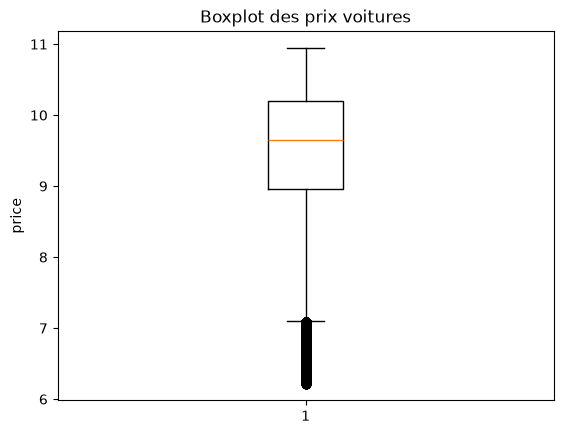

In [11]:
import matplotlib.pyplot as plt

plt.boxplot(df_encoded["price"])

plt.ylabel("price")
plt.title("Boxplot des prix voitures")

plt.show()

In [12]:
df_encoded.to_csv('data/vehicles_encoded.csv', index=False)

In [13]:
import json

data = {
    "manufacturers": sorted(df_ml['manufacturer'].dropna().unique().tolist()),
    "fuels": sorted(df_ml['fuel'].dropna().unique().tolist()),
    "transmissions": sorted(df_ml['transmission'].dropna().unique().tolist()),
    "title_status": sorted(df_ml['title_status'].dropna().unique().tolist()),
    "types": sorted(df_ml['type'].dropna().unique().tolist()),
    "states": sorted(df_ml['state'].dropna().unique().tolist())
}

with open('data/options.json', 'w') as f:
    json.dump(data, f)


In [14]:
print(df_encoded.columns.tolist())
print(df_ml['year'].min())
print(df_ml['year'].max())

['year', 'odometer', 'price', 'year_squared', 'odometer_squared', 'car_age', 'age_odometer_interaction', 'manufacturer_acura', 'manufacturer_alfa-romeo', 'manufacturer_aston-martin', 'manufacturer_audi', 'manufacturer_bmw', 'manufacturer_buick', 'manufacturer_cadillac', 'manufacturer_chevrolet', 'manufacturer_chrysler', 'manufacturer_datsun', 'manufacturer_dodge', 'manufacturer_ferrari', 'manufacturer_fiat', 'manufacturer_ford', 'manufacturer_gmc', 'manufacturer_harley-davidson', 'manufacturer_honda', 'manufacturer_hyundai', 'manufacturer_infiniti', 'manufacturer_jaguar', 'manufacturer_jeep', 'manufacturer_kia', 'manufacturer_land rover', 'manufacturer_lexus', 'manufacturer_lincoln', 'manufacturer_mazda', 'manufacturer_mercedes-benz', 'manufacturer_mercury', 'manufacturer_mini', 'manufacturer_mitsubishi', 'manufacturer_morgan', 'manufacturer_nissan', 'manufacturer_pontiac', 'manufacturer_porsche', 'manufacturer_ram', 'manufacturer_rover', 'manufacturer_saturn', 'manufacturer_subaru', '